In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
df = pd.read_csv("data/city_day.csv", parse_dates=["Date"])
print(df.shape)
print(df["City"].unique())
df.head()

(29531, 16)
<ArrowStringArray>
[         'Ahmedabad',             'Aizawl',          'Amaravati',
           'Amritsar',          'Bengaluru',             'Bhopal',
       'Brajrajnagar',         'Chandigarh',            'Chennai',
         'Coimbatore',              'Delhi',          'Ernakulam',
           'Gurugram',           'Guwahati',          'Hyderabad',
             'Jaipur',         'Jorapokhar',              'Kochi',
            'Kolkata',            'Lucknow',             'Mumbai',
              'Patna',           'Shillong',            'Talcher',
 'Thiruvananthapuram',      'Visakhapatnam']
Length: 26, dtype: str


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
CITY = "Delhi"
data = df[df["City"] == CITY].set_index("Date").sort_index()
features = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "AQI"]
data = data[features]
print(data.shape)
print(data.isnull().sum())
data.describe()


(2009, 7)
PM2.5      2
PM10      77
NO2        2
SO2      110
CO         0
O3        84
AQI       10
dtype: int64


,PM2.5,PM10,NO2,SO2,CO,O3,AQI
count,2007.000000,1932.000000,2007.000000,1899.000000,2009.000000,1925.00000,1999.000000
mean,117.196153,232.809229,50.785182,15.901253,1.976053,51.32361,259.487744
std,82.912945,121.873025,22.696721,7.966770,2.560253,26.06234,119.537333
min,10.240000,18.590000,10.630000,2.340000,0.000000,6.94000,29.000000
25%,57.095000,137.040000,33.895000,10.335000,0.910000,33.71000,161.500000
50%,94.620000,216.730000,47.150000,14.450000,1.240000,44.44000,257.000000
75%,153.030000,311.667500,63.570000,19.700000,1.870000,60.84000,345.500000
max,685.360000,796.880000,162.500000,71.560000,30.440000,257.73000,716.000000


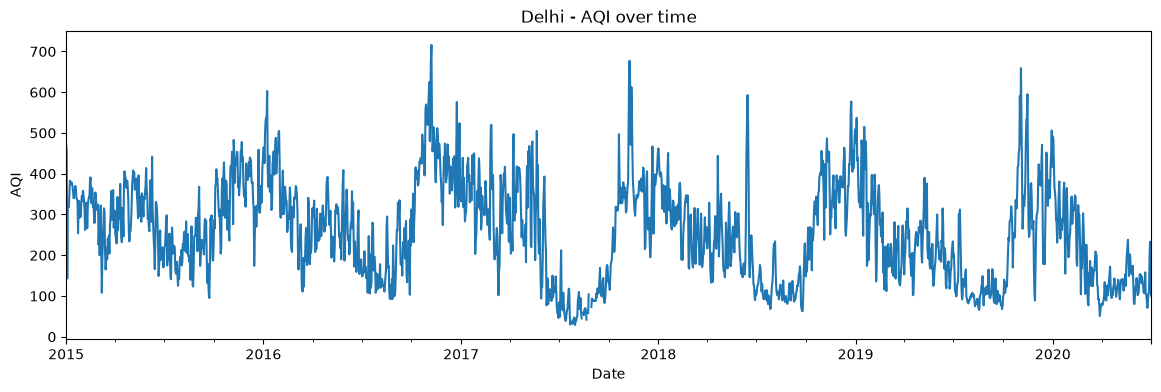

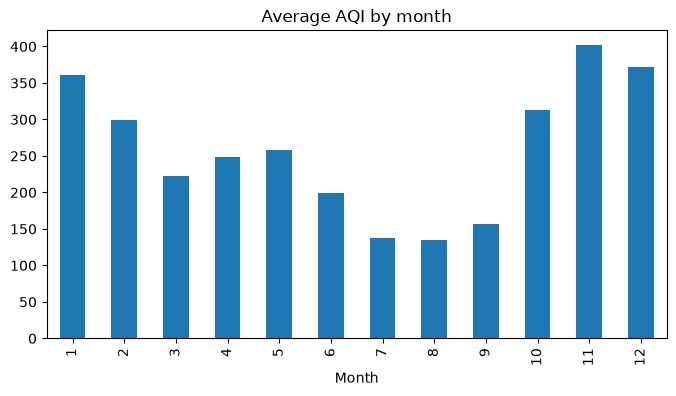

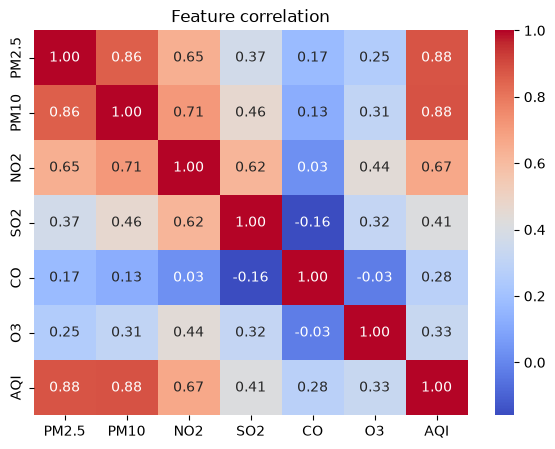

In [4]:
data["AQI"].plot(figsize=(14, 4), title=f"{CITY} - AQI over time")
plt.ylabel("AQI"); plt.show()

data.groupby(data.index.month)["AQI"].mean().plot(kind="bar", figsize=(8, 4), title="Average AQI by month")
plt.xlabel("Month"); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation"); plt.show()

In [5]:
data = data.interpolate(method="time").bfill().ffill()
print(data.isnull().sum().sum(), "missing values bache")

0 missing values bache


In [6]:
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]

scaler = MinMaxScaler()
scaler.fit(train)
train_s = scaler.transform(train)
test_s = scaler.transform(test)
print(len(train), len(test))

1607 402


In [7]:
WINDOW = 30
target_idx = features.index("AQI")

def make_sequences(arr, window, target):
    X, y = [], []
    for i in range(window, len(arr)):
        X.append(arr[i - window:i])
        y.append(arr[i, target])
    return np.array(X), np.array(y)

X_train, y_train = make_sequences(train_s, WINDOW, target_idx)
test_input = np.vstack([train_s[-WINDOW:], test_s])
X_test, y_test = make_sequences(test_input, WINDOW, target_idx)
print(X_train.shape, X_test.shape)

(1577, 30, 7) (402, 30, 7)


In [8]:
model = Sequential([
    Input(shape=(WINDOW, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0220 - val_loss: 0.0130
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0126 - val_loss: 0.0121
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0117 - val_loss: 0.0140
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0116 - val_loss: 0.0130
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0111 - val_loss: 0.0129
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0110 - val_loss: 0.0115
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0103 - val_loss: 0.0124
Epoch 8/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0098 - val_loss: 0.0105
Epoch 9/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0096 - val_loss: 0.0106
Epoch 10/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0094 - val_loss: 0.0107
Epoch 11/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0090 - val_loss: 0.0098
Epoch 12/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0

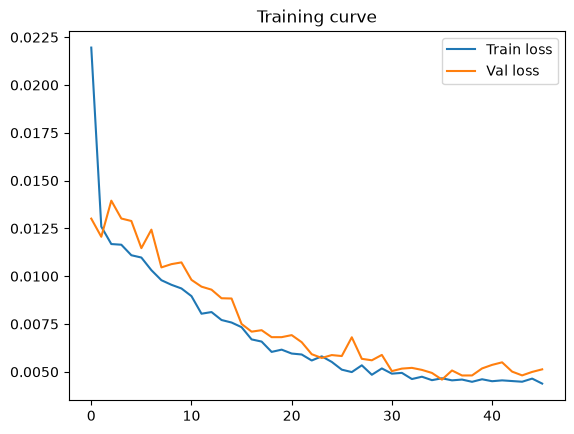

In [9]:
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Val loss")
plt.legend(); plt.title("Training curve"); plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
LSTM               RMSE:   38.87 | MAE:   27.81 | R2: 0.883


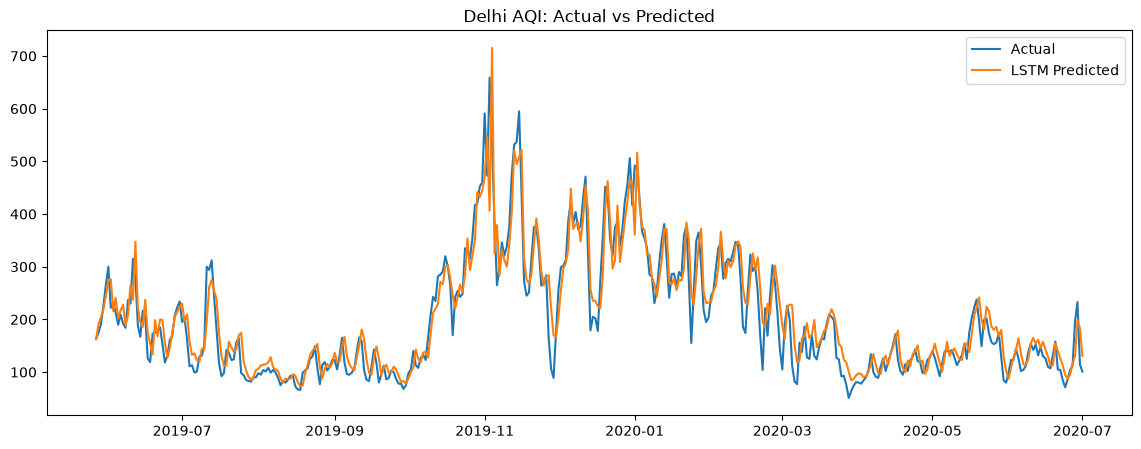

In [10]:
def inverse_aqi(values):
    dummy = np.zeros((len(values), len(features)))
    dummy[:, target_idx] = values
    return scaler.inverse_transform(dummy)[:, target_idx]

pred = inverse_aqi(model.predict(X_test).flatten())
actual = inverse_aqi(y_test)

def report(name, actual, pred):
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)
    print(f"{name:18s} RMSE: {rmse:7.2f} | MAE: {mae:7.2f} | R2: {r2:.3f}")
    return rmse, mae, r2

lstm_scores = report("LSTM", actual, pred)

plt.figure(figsize=(14, 5))
plt.plot(test.index, actual, label="Actual")
plt.plot(test.index, pred, label="LSTM Predicted")
plt.legend(); plt.title(f"{CITY} AQI: Actual vs Predicted"); plt.show()

In [11]:
naive_pred = inverse_aqi(X_test[:, -1, target_idx])
report("Naive (yesterday)", actual, naive_pred)

lr = LinearRegression()
lr.fit(X_train.reshape(len(X_train), -1), y_train)
lr_pred = inverse_aqi(lr.predict(X_test.reshape(len(X_test), -1)))
report("Linear Regression", actual, lr_pred)

Naive (yesterday)  RMSE:   44.97 | MAE:   31.46 | R2: 0.843
Linear Regression  RMSE:   35.61 | MAE:   25.48 | R2: 0.901


(np.float64(35.608491545048814), 25.479853085412614, 0.9014286511076148)

In [12]:
def forecast_next(model, last_window, steps=7):
    window = last_window.copy()
    preds = []
    for _ in range(steps):
        p = model.predict(window[np.newaxis, :, :], verbose=0)[0, 0]
        preds.append(p)
        new_row = window[-1].copy()
        new_row[target_idx] = p
        window = np.vstack([window[1:], new_row])
    return inverse_aqi(np.array(preds))

last_window = scaler.transform(data.iloc[-WINDOW:])
future = forecast_next(model, last_window, steps=7)
future_dates = pd.date_range(data.index[-1] + pd.Timedelta(days=1), periods=7)
print(pd.Series(future, index=future_dates).round(1))

2020-07-02    126.6
2020-07-03    130.0
2020-07-04    132.9
2020-07-05    135.5
2020-07-06    137.6
2020-07-07    139.5
2020-07-08    141.4
Freq: D, dtype: float64


In [13]:
import joblib
model.save("aqi_lstm_model.keras")
joblib.dump(scaler, "scaler.pkl")
print("Saved!")

Saved!


In [14]:
from tensorflow.keras.layers import GRU

def run_experiment(window, kind="LSTM", units=32):
    Xtr, ytr = make_sequences(train_s, window, target_idx)
    test_in = np.vstack([train_s[-window:], test_s])
    Xte, yte = make_sequences(test_in, window, target_idx)
    Layer = LSTM if kind == "LSTM" else GRU
    tf.random.set_seed(42)
    m = Sequential([
        Input(shape=(window, len(features))),
        Layer(units),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    m.fit(Xtr, ytr, epochs=100, batch_size=32, validation_split=0.1,
          callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
          verbose=0)
    p = inverse_aqi(m.predict(Xte, verbose=0).flatten())
    a = inverse_aqi(yte)
    return p, a

rows = []
all_preds = {}
for kind in ["LSTM", "GRU"]:
    for w in [7, 14, 30]:
        p, a = run_experiment(w, kind)
        name = f"{kind} (window={w})"
        rmse, mae, r2 = report(name, a, p)
        rows.append([name, rmse, mae, r2])
        all_preds[name] = p

# Linear Regression bhi same windows pe
for w in [7, 14, 30]:
    Xtr, ytr = make_sequences(train_s, w, target_idx)
    test_in = np.vstack([train_s[-w:], test_s])
    Xte, yte = make_sequences(test_in, w, target_idx)
    lr_w = LinearRegression().fit(Xtr.reshape(len(Xtr), -1), ytr)
    p = inverse_aqi(lr_w.predict(Xte.reshape(len(Xte), -1)))
    name = f"LinearReg (window={w})"
    rmse, mae, r2 = report(name, inverse_aqi(yte), p)
    rows.append([name, rmse, mae, r2])
    all_preds[name] = p

rows.append(["Naive (yesterday)", *report("Naive (yesterday)", actual, naive_pred)])

LSTM (window=7)    RMSE:   36.96 | MAE:   26.01 | R2: 0.894
LSTM (window=14)   RMSE:   37.36 | MAE:   26.26 | R2: 0.891
LSTM (window=30)   RMSE:   35.16 | MAE:   24.55 | R2: 0.904
GRU (window=7)     RMSE:   37.31 | MAE:   26.85 | R2: 0.892
GRU (window=14)    RMSE:   34.56 | MAE:   24.02 | R2: 0.907
GRU (window=30)    RMSE:   35.04 | MAE:   24.59 | R2: 0.905
LinearReg (window=7) RMSE:   35.78 | MAE:   26.01 | R2: 0.900
LinearReg (window=14) RMSE:   35.41 | MAE:   25.54 | R2: 0.903
LinearReg (window=30) RMSE:   35.61 | MAE:   25.48 | R2: 0.901
Naive (yesterday)  RMSE:   44.97 | MAE:   31.46 | R2: 0.843


In [15]:
results = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "R2"]).sort_values("RMSE").reset_index(drop=True)
results.round(3)

,Model,RMSE,MAE,R2
0,GRU (window=14),34.563,24.019,0.907
1,GRU (window=30),35.042,24.593,0.905
2,LSTM (window=30),35.158,24.554,0.904
3,LinearReg (window=14),35.409,25.536,0.903
4,LinearReg (window=30),35.608,25.480,0.901
5,LinearReg (window=7),35.781,26.010,0.900
6,LSTM (window=7),36.956,26.005,0.894
7,GRU (window=7),37.315,26.847,0.892
8,LSTM (window=14),37.360,26.261,0.891
9,Naive (yesterday),44.969,31.463,0.843


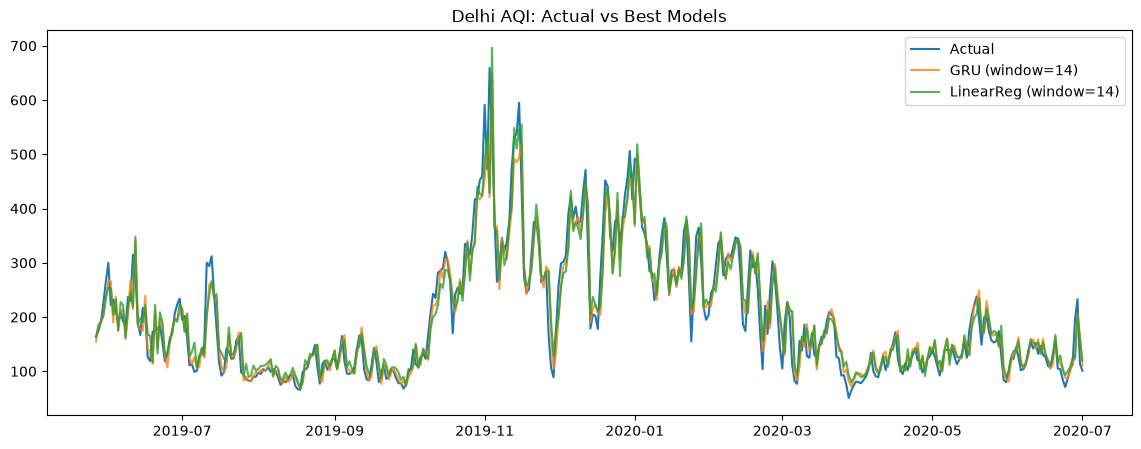

Best deep model: GRU (window=14)


In [16]:
deep_only = results[results["Model"].str.contains("LSTM|GRU")]
best_deep = deep_only.iloc[0]["Model"]
best_lr = results[results["Model"].str.contains("LinearReg")].iloc[0]["Model"]

plt.figure(figsize=(14, 5))
plt.plot(test.index, actual, label="Actual", linewidth=1.5)
plt.plot(test.index, all_preds[best_deep], label=best_deep, alpha=0.8)
plt.plot(test.index, all_preds[best_lr], label=best_lr, alpha=0.8)
plt.legend(); plt.title(f"{CITY} AQI: Actual vs Best Models"); plt.show()
print("Best deep model:", best_deep)

results.to_csv("model_comparison.csv", index=False)

In [17]:
import joblib

WINDOW = 30
Xtr, ytr = make_sequences(train_s, WINDOW, target_idx)
test_in = np.vstack([train_s[-WINDOW:], test_s])
Xte, yte = make_sequences(test_in, WINDOW, target_idx)

tf.random.set_seed(42)
final_model = Sequential([
    Input(shape=(WINDOW, len(features))),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
final_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
hist = final_model.fit(Xtr, ytr, epochs=100, batch_size=32, validation_split=0.1,
                       callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
                       verbose=0)

final_pred = inverse_aqi(final_model.predict(Xte, verbose=0).flatten())
final_actual = inverse_aqi(yte)
report("Final LSTM (w=30)", final_actual, final_pred)

final_model.save("aqi_lstm_final.keras")
joblib.dump(scaler, "scaler.pkl")

future = forecast_next(final_model, scaler.transform(data.iloc[-WINDOW:]), steps=7)
future_dates = pd.date_range(data.index[-1] + pd.Timedelta(days=1), periods=7)
print(pd.Series(future, index=future_dates).round(1))

Final LSTM (w=30)  RMSE:   35.68 | MAE:   24.80 | R2: 0.901
2020-07-02    119.0
2020-07-03    122.2
2020-07-04    124.3
2020-07-05    125.8
2020-07-06    126.9
2020-07-07    127.8
2020-07-08    128.6
Freq: D, dtype: float64


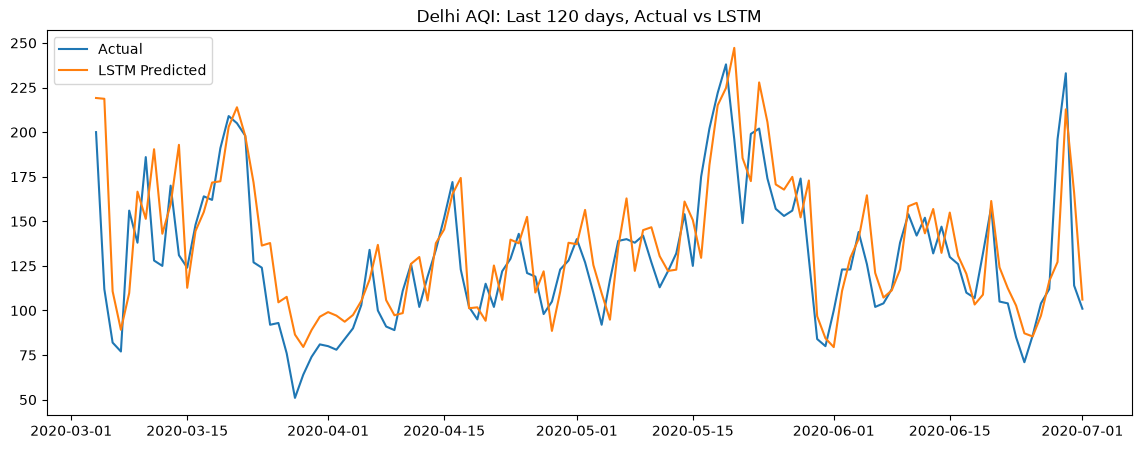

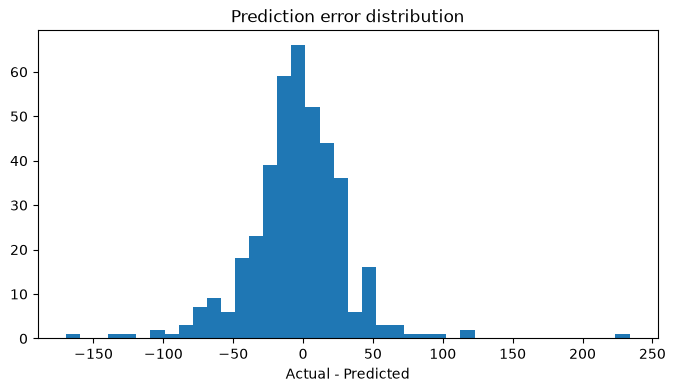

In [18]:
# Last 120 din ka zoomed graph (padhne mein easy)
plt.figure(figsize=(14, 5))
plt.plot(test.index[-120:], final_actual[-120:], label="Actual")
plt.plot(test.index[-120:], final_pred[-120:], label="LSTM Predicted")
plt.legend(); plt.title(f"{CITY} AQI: Last 120 days, Actual vs LSTM"); plt.show()

# Error distribution
errors = final_actual - final_pred
plt.figure(figsize=(8, 4))
plt.hist(errors, bins=40)
plt.title("Prediction error distribution"); plt.xlabel("Actual - Predicted"); plt.show()

In [19]:
import os, json, joblib
os.makedirs("models", exist_ok=True)

counts = df.groupby("City")["AQI"].count()
avg = df.groupby("City")["AQI"].mean()
eligible = avg[counts >= 1000].sort_values(ascending=False)
TOP_CITIES = list(eligible.head(8).index)
print("Top polluted cities:", TOP_CITIES)

def train_city(city, window=30):
    d = df[df["City"] == city].set_index("Date").sort_index()[features]
    d = d.loc[d["AQI"].first_valid_index(): d["AQI"].last_valid_index()]
    d = d.interpolate(method="time").bfill().ffill().fillna(0)

    split = int(len(d) * 0.8)
    train_d, test_d = d.iloc[:split], d.iloc[split:]
    sc = MinMaxScaler().fit(train_d)
    tr, te = sc.transform(train_d), sc.transform(test_d)

    Xtr, ytr = make_sequences(tr, window, target_idx)
    Xte, yte = make_sequences(np.vstack([tr[-window:], te]), window, target_idx)

    tf.random.set_seed(42)
    m = Sequential([
        Input(shape=(window, len(features))),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    m.fit(Xtr, ytr, epochs=100, batch_size=32, validation_split=0.1,
          callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
          verbose=0)

    def inv(v):
        dummy = np.zeros((len(v), len(features)))
        dummy[:, target_idx] = v
        return sc.inverse_transform(dummy)[:, target_idx]

    p = inv(m.predict(Xte, verbose=0).flatten())
    a = inv(yte)
    naive = inv(Xte[:, -1, target_idx])

    m.save(f"models/{city}.keras")
    joblib.dump(sc, f"models/{city}_scaler.pkl")
    d.tail(120).to_csv(f"models/{city}_recent.csv")
    pd.DataFrame({"Date": test_d.index, "Actual": a, "Predicted": p}).tail(90).to_csv(
        f"models/{city}_backtest.csv", index=False)

    return {
        "rmse": float(np.sqrt(mean_squared_error(a, p))),
        "mae": float(mean_absolute_error(a, p)),
        "r2": float(r2_score(a, p)),
        "naive_rmse": float(np.sqrt(mean_squared_error(a, naive))),
        "avg_aqi": float(d["AQI"].mean()),
        "n_days": int(len(d)),
    }

summary = {}
for c in TOP_CITIES:
    print("Training:", c)
    summary[c] = train_city(c)
    print({k: round(v, 3) for k, v in summary[c].items()})

json.dump(summary, open("models/summary.json", "w"), indent=2)
print("Done! Saari cities ready.")

Top polluted cities: ['Ahmedabad', 'Delhi', 'Patna', 'Gurugram', 'Lucknow', 'Jaipur', 'Amritsar', 'Visakhapatnam']
Training: Ahmedabad
{'rmse': 286.785, 'mae': 241.084, 'r2': -0.354, 'naive_rmse': 160.427, 'avg_aqi': 399.052, 'n_days': 1981}
Training: Delhi
{'rmse': 37.477, 'mae': 27.025, 'r2': 0.891, 'naive_rmse': 44.969, 'avg_aqi': 258.621, 'n_days': 2009}
Training: Patna
{'rmse': 328.552, 'mae': 227.371, 'r2': -8.955, 'naive_rmse': 36.848, 'avg_aqi': 233.854, 'n_days': 1734}
Training: Gurugram
{'rmse': 40.952, 'mae': 29.18, 'r2': 0.843, 'naive_rmse': 45.531, 'avg_aqi': 227.99, 'n_days': 1622}
Training: Lucknow
{'rmse': 28.791, 'mae': 21.685, 'r2': 0.915, 'naive_rmse': 40.133, 'avg_aqi': 217.013, 'n_days': 1930}
Training: Jaipur
{'rmse': 17.691, 'mae': 13.29, 'r2': 0.59, 'naive_rmse': 21.17, 'avg_aqi': 133.28, 'n_days': 1108}
Training: Amritsar
{'rmse': 44.332, 'mae': 25.828, 'r2': 0.567, 'naive_rmse': 51.105, 'avg_aqi': 122.448, 'n_days': 1220}
Training: Visakhapatnam
{'rmse': 26.70